# 3-fish control: where the emitter is when it is far from the other fish

EODs of the 3-fish control (2024-10-15) with the emitter (fish 0, ZEUS 0) at least **25 cm** from both other fish (`gap_cm`, smallest
mask-edge distance, EOD frame). For these EODs, from the ZEUS masks of the EOD frame:
- **body occupancy**: % of these EODs in which each pixel is covered by fish 0's mask, over the median video frame (fish removed),
  with the electrode pairs (+ red, − blue);
- **tail tip**: where fish 0's tail tip (end of the mask midline, the sink of my model) is, and centroid → tail tip by outcome;
- **position and heading**: mask centroid and head of fish 0 (mask midline), coloured by the outcome of my numerical model (shape,
  sink at the tail tip) and Denis' analytic model with my mask midline, both at the EOD frame (no offset).

Two sets: all EODs, and those in the better list of good frames. % correct of every pipeline on these EODs is in the table at the end.

In [1]:
import os
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import eod_examples as ex
%matplotlib inline

GAP_CM = 25
OUT = 'results/eod_ground_truth_3fish/conductivities/far_emitter_positions'; os.makedirs(OUT, exist_ok=True)
c = ex.load_recording('3-fish'); P, EM = c['P'], c['emitter']
A = c['assigned']
picks = pd.read_csv('results/baseline_g0/vs_distance/picks_3-fish.csv', index_col='row')
assert (picks.Frame.to_numpy() == A.Frame.to_numpy()).all()
better = picks['better list'].to_numpy()
far = (A.gap_cm >= GAP_CM).to_numpy()
SETS = {'all EODs': far, 'better list of good frames': far & better}
print({s: int(m.sum()) for s, m in SETS.items()}, '| distinct frames:', A.Frame[far].nunique())

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b'})

{'all EODs': 2380, 'better list of good frames': 423} | distinct frames: 2369


## Fish 0 per EOD: mask, centroid, head and tail tip

In [2]:
def fish0(k):
    m = ex.frame_masks(c, int(k))[EM]
    if not m.any(): return int(k), None, np.full(2, np.nan), np.full(2, np.nan), np.full(2, np.nan)
    yx = np.argwhere(m); mid = ex.fish_midlines([m])[0]
    head = mid[-1] * (P - 1) if mid is not None else np.full(2, np.nan)
    tail = mid[0] * (P - 1) if mid is not None else np.full(2, np.nan)   # tail tip (the sink of my model)
    return int(k), np.packbits(m), yx.mean(0), head, tail               # (row, col) px

frames = np.unique(A.Frame[far])
with mp.get_context('fork').Pool(7) as pool:
    res = pool.map(fish0, frames, chunksize=8)
F = {k: (pk, cen, hd, tl) for k, pk, cen, hd, tl in res}
pos = pd.DataFrame({'Frame': A.Frame[far], 'gap_cm': A.gap_cm[far],
                    'cy': [F[k][1][0] for k in A.Frame[far]], 'cx': [F[k][1][1] for k in A.Frame[far]],
                    'hy': [F[k][2][0] for k in A.Frame[far]], 'hx': [F[k][2][1] for k in A.Frame[far]],
                    'ty': [F[k][3][0] for k in A.Frame[far]], 'tx': [F[k][3][1] for k in A.Frame[far]],
                    'better list': better[far]}, index=A.index[far])
mine = picks.loc[pos.index, 'numerical, shape'] == EM; den = picks.loc[pos.index, 'analytic, mask midline'] == EM
pos['outcome'] = np.select([mine & den, mine & ~den, ~mine & den], ['both right', 'only mine right', 'only Denis right'], 'both wrong')
pos.to_csv(f'{OUT}/far_emitter_positions.csv')
display(pos.groupby('better list').outcome.value_counts().unstack(fill_value=0))

# median video frame (fish removed) as background
bg = np.median(np.stack([ex.video_frame(c, int(k)) for k in np.linspace(0, len(c['frames']) - 1, 41).astype(int)]), axis=0)

outcome,both right,both wrong,only Denis right,only mine right
better list,,,,
False,1595,311,23,28
True,408,11,3,1


## Spatial distribution

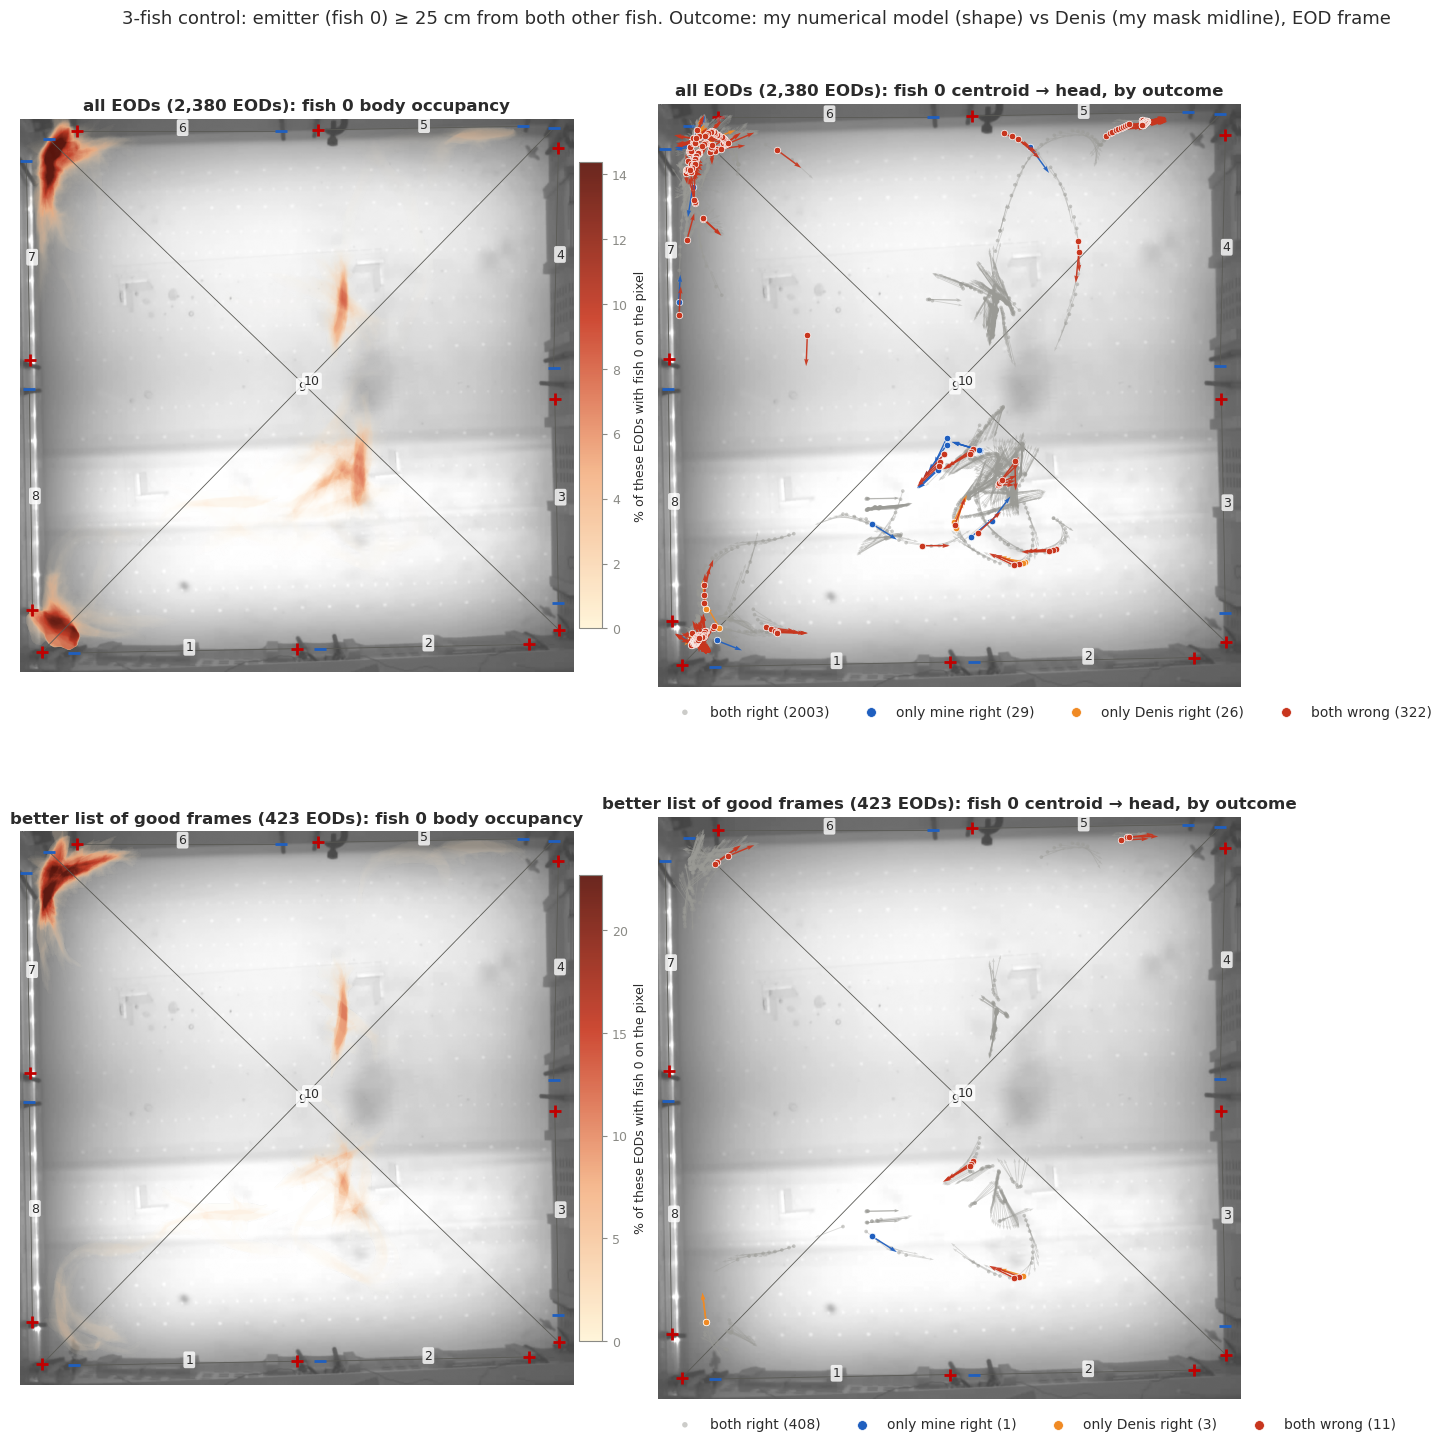

In [3]:
OCC_CMAP = LinearSegmentedColormap.from_list('occ', ['#FFF4D600', '#F4B183', '#C8361E', '#5A0F06'])
OUT_COL = {'both right': '#9a9a95', 'only mine right': '#1F5FBF', 'only Denis right': '#F08A24', 'both wrong': '#C8361E'}

def electrodes(a):
    for pid, pp, pm in c['pairs']:
        (yp, xp), (ym, xm) = pp * (P - 1), pm * (P - 1)
        a.plot([xp, xm], [yp, ym], color='#5a5a55', lw=0.6, zorder=3)
        a.plot(xp, yp, '+', color='#C00000', ms=9, mew=2, zorder=4); a.plot(xm, ym, '_', color='#1F5FBF', ms=9, mew=2, zorder=4)
        a.text((xp + xm) / 2, (yp + ym) / 2, str(pid), color='#2b2b2b', fontsize=9, zorder=5,
               bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

fig, axs = plt.subplots(2, 2, figsize=(15, 15))
for row, (s, m) in zip(axs, SETS.items()):
    sub = pos[m[far]]
    occ = np.zeros((P, P))
    for k, n in sub.Frame.value_counts().items():
        occ += n * np.unpackbits(F[k][0])[:P * P].reshape(P, P)
    occ = 100 * occ / len(sub)
    a = row[0]; a.imshow(bg, cmap='gray', vmin=0, vmax=255)
    im = a.imshow(np.ma.masked_less(occ, 0.05), cmap=OCC_CMAP, vmin=0, vmax=np.percentile(occ[occ > 0], 99.5), alpha=0.9)
    electrodes(a); a.set_axis_off()
    a.set_title(f'{s} ({len(sub):,} EODs): fish 0 body occupancy', fontsize=12)
    fig.colorbar(im, ax=a, fraction=0.04, pad=0.01, label='% of these EODs with fish 0 on the pixel')
    a = row[1]; a.imshow(bg, cmap='gray', vmin=0, vmax=255)
    for o in ['both right', 'only mine right', 'only Denis right', 'both wrong']:
        q = sub[sub.outcome == o]
        if not len(q): continue
        big = o != 'both right'
        a.quiver(q.cx, q.cy, q.hx - q.cx, q.hy - q.cy, angles='xy', scale_units='xy', scale=1.6, width=0.0025 if big else 0.0015,
                 color=OUT_COL[o], alpha=0.95 if big else 0.35, zorder=6 if big else 5)
        a.scatter(q.cx, q.cy, s=22 if big else 7, color=OUT_COL[o], ec='white' if big else 'none', lw=0.5, zorder=6 if big else 5,
                  alpha=1 if big else 0.5, label=f'{o} ({len(q)})')
    electrodes(a); a.set_axis_off()
    a.set_title(f'{s} ({len(sub):,} EODs): fish 0 centroid → head, by outcome', fontsize=12)
    a.legend(loc='upper left', bbox_to_anchor=(0, -0.01), ncol=4, frameon=False, fontsize=10, markerscale=1.5)
fig.suptitle(f'3-fish control: emitter (fish 0) ≥ {GAP_CM} cm from both other fish. Outcome: my numerical model (shape) vs Denis (my mask midline), EOD frame',
             fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.98)); fig.savefig(f'{OUT}/far_emitter_positions_{GAP_CM}cm.png', dpi=110); plt.show()

## Tail tip
Left: % of these EODs with fish 0's tail tip in each 1 cm square (15 px bins). Right: centroid → tail tip, by outcome.

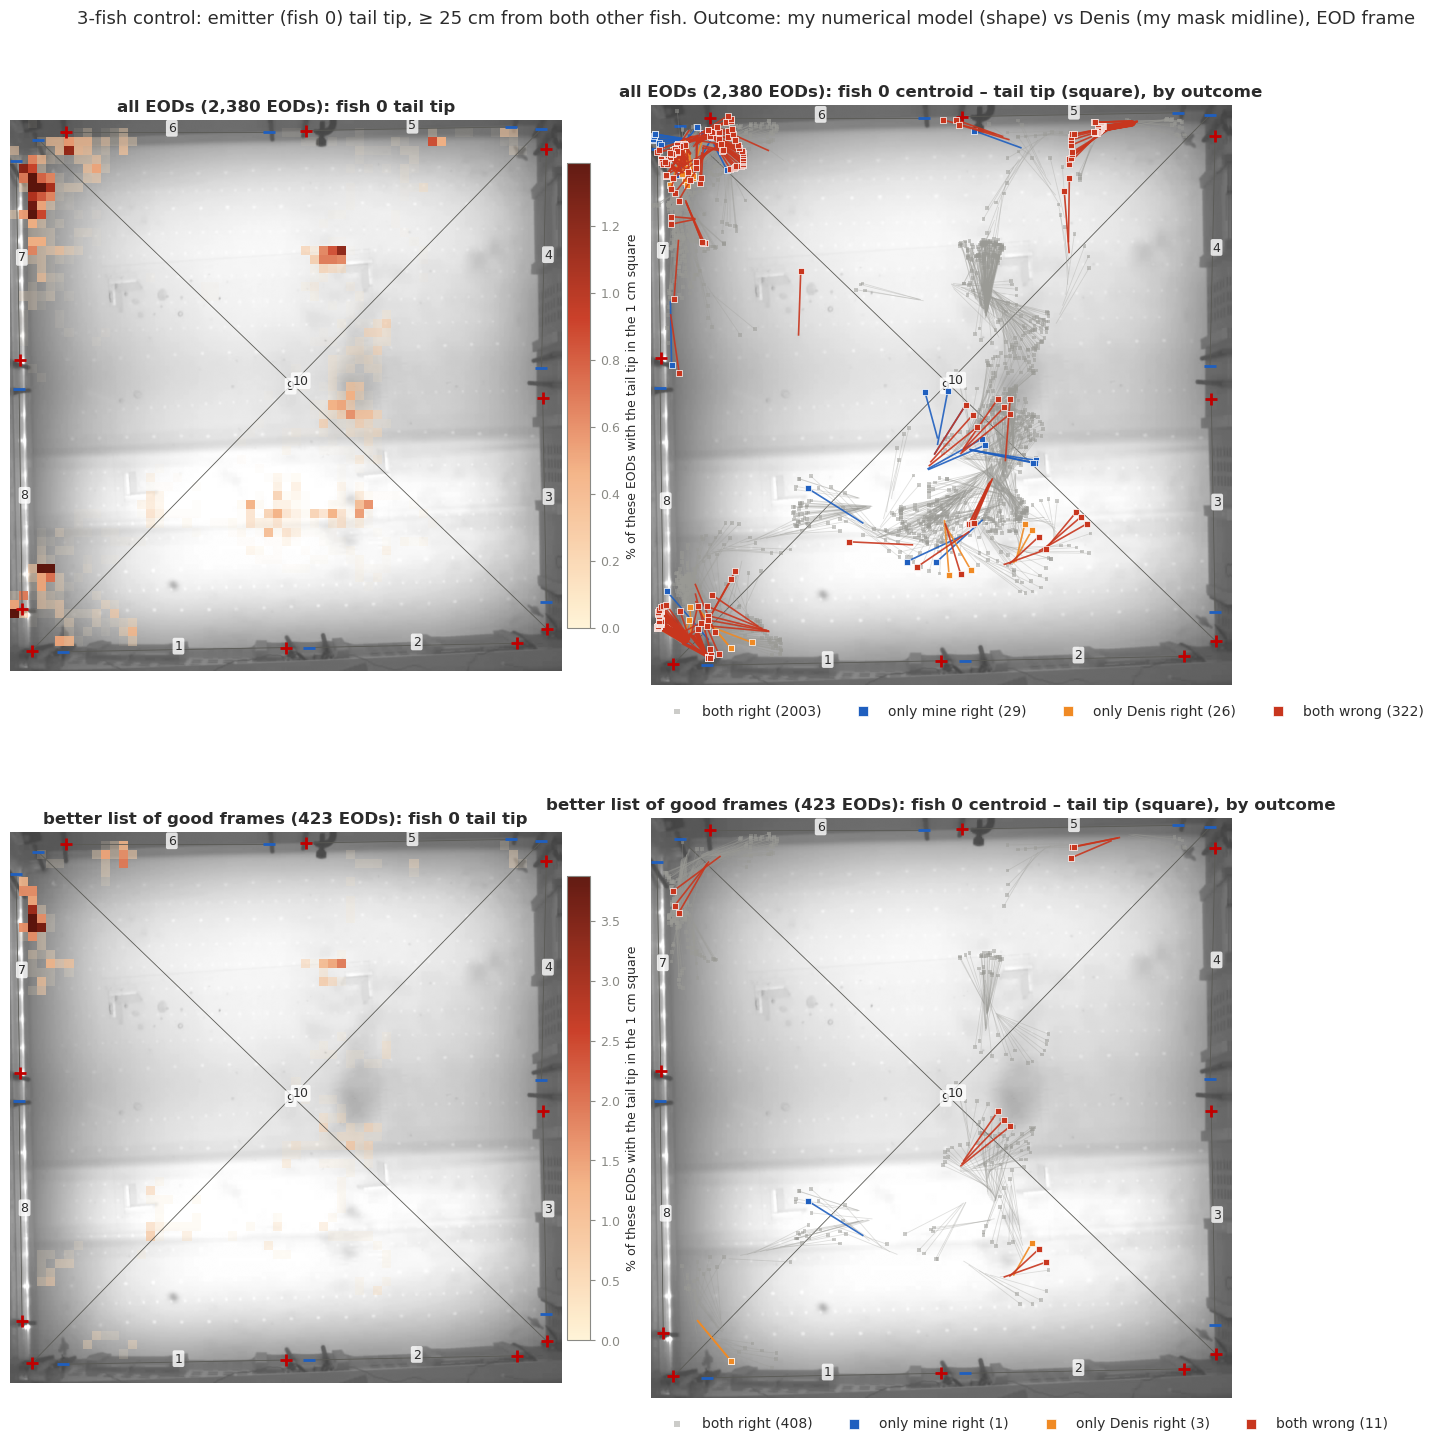

In [4]:
B = 15
fig, axs = plt.subplots(2, 2, figsize=(15, 15))
for row, (s, m) in zip(axs, SETS.items()):
    sub = pos[m[far]].dropna(subset=['tx', 'ty'])
    H, ye, xe = np.histogram2d(sub.ty, sub.tx, bins=[np.arange(0, P + B, B)] * 2)
    H = 100 * H / len(sub)
    a = row[0]; a.imshow(bg, cmap='gray', vmin=0, vmax=255)
    im = a.imshow(np.ma.masked_equal(H, 0), cmap=OCC_CMAP, extent=(xe[0], xe[-1], ye[-1], ye[0]), interpolation='nearest',
                  vmin=0, vmax=np.percentile(H[H > 0], 99), alpha=0.95)
    electrodes(a); a.set(xlim=(0, P), ylim=(P, 0)); a.set_axis_off()
    a.set_title(f'{s} ({len(sub):,} EODs): fish 0 tail tip', fontsize=12)
    fig.colorbar(im, ax=a, fraction=0.04, pad=0.01, label='% of these EODs with the tail tip in the 1 cm square')
    a = row[1]; a.imshow(bg, cmap='gray', vmin=0, vmax=255)
    for o in ['both right', 'only mine right', 'only Denis right', 'both wrong']:
        q = sub[sub.outcome == o]
        if not len(q): continue
        big = o != 'both right'
        a.plot(np.c_[q.cx, q.tx].T, np.c_[q.cy, q.ty].T, color=OUT_COL[o], lw=1.2 if big else 0.6, alpha=0.9 if big else 0.3, zorder=6 if big else 5)
        a.scatter(q.tx, q.ty, s=22 if big else 7, marker='s', color=OUT_COL[o], ec='white' if big else 'none', lw=0.5,
                  zorder=6 if big else 5, alpha=1 if big else 0.5, label=f'{o} ({len(q)})')
    electrodes(a); a.set(xlim=(0, P), ylim=(P, 0)); a.set_axis_off()
    a.set_title(f'{s} ({len(sub):,} EODs): fish 0 centroid – tail tip (square), by outcome', fontsize=12)
    a.legend(loc='upper left', bbox_to_anchor=(0, -0.01), ncol=4, frameon=False, fontsize=10, markerscale=1.5)
fig.suptitle(f'3-fish control: emitter (fish 0) tail tip, ≥ {GAP_CM} cm from both other fish. Outcome: my numerical model (shape) vs Denis (my mask midline), EOD frame',
             fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.98)); fig.savefig(f'{OUT}/far_emitter_tail_{GAP_CM}cm.png', dpi=110); plt.show()

## % correct on these EODs

In [5]:
def wilson(k, n, z=1.96):
    p = k / n; cc = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (cc - hw), 100 * (cc + hw)
pipes = [p for p in picks.columns if p not in ('Frame', 'gap_cm', 'better list')]
rows = []
for s, m in SETS.items():
    for p in pipes:
        k, n = int((picks.loc[m, p] == EM).sum()), int(m.sum()); lo, hi = wilson(k, n)
        rows.append({'EODs': f'{s}, fish 0 ≥ {GAP_CM} cm', 'pipeline': p, '% correct': 100 * k / n, '95% CI low': lo, '95% CI high': hi, 'n EODs': n})
T = pd.DataFrame(rows); T.to_csv(f'{OUT}/accuracy_far_emitter_{GAP_CM}cm.csv', index=False)
display(T.pivot_table(index='pipeline', columns='EODs', values='% correct', sort=False).round(2))

EODs,"all EODs, fish 0 ≥ 25 cm","better list of good frames, fish 0 ≥ 25 cm"
pipeline,,
"analytic, SLEAP midline",78.07,96.45
"analytic, mask midline",85.25,97.16
"numerical, shape",85.38,96.69
"numerical, voltage, own g0",85.25,97.87
"numerical, voltage, 4-fish g0",85.42,98.11
"numerical, voltage, own g0, best offset",86.97,99.05
"analytic, mask midline, best offset",86.76,99.53
